In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
TH99=0.14655972998295605
TH95=0.10024662155621214
# df must contain:
# patient_id, risk_t0, screen_date, event_date
# screen_date and event_date are integers on the same time scale
# event_date can be missing if event never occurred

def make_km_plot(
    df,
    screen_col="screen_date",
    event_col="event_date",
    risk_col="risk_t0",
    max_followup=5,
    risk_split="median",   # "median", numeric threshold, or None
    title="Kaplan-Meier curve",
    time_unit_label="Time since screening"
):
    d = df.copy()

    # Coerce to numeric
    d[screen_col] = pd.to_numeric(d[screen_col], errors="coerce")
    d[event_col] = pd.to_numeric(d[event_col], errors="coerce")
    d[risk_col] = pd.to_numeric(d[risk_col], errors="coerce")

    # Drop rows with invalid screening time or missing risk
    d = d[d[screen_col].notna() & d[risk_col].notna()].copy()

    # Time from screening to event
    time_to_event = d[event_col] - d[screen_col]

    # Event observed only if:
    #   event exists
    #   event_date >= screen_date
    #   event occurs within follow-up window
    d["event_observed"] = (
        d[event_col].notna() &
        (d[event_col] >= d[screen_col]) &
        (time_to_event <= max_followup)
    ).astype(int)

    # Observed time:
    # actual time if valid observed event, otherwise censor at max_followup
    d["time"] = np.where(
        d["event_observed"] == 1,
        time_to_event,
        max_followup
    )

    # Remove negative observed/censor times if any weird rows remain
    d = d[d["time"] >= 0].copy()

    plt.figure(figsize=(8, 6))
    kmf = KaplanMeierFitter()

    if risk_split == "median":
        thr = d[risk_col].median()
        d["risk_group"] = np.where(d[risk_col] >= thr, "High risk", "Low risk")

        for grp in ["High risk", "Low risk"]:
            sub = d[d["risk_group"] == grp]
            if len(sub) == 0:
                continue
            kmf.fit(
                durations=sub["time"],
                event_observed=sub["event_observed"],
                label=f"{grp} (n={len(sub)})"
            )
            kmf.plot_survival_function(ci_show=True)

        plt.title(f"{title}\nSplit at median {risk_col} = {thr:.4f}")

    elif isinstance(risk_split, (int, float)):
        thr = float(risk_split)
        d["risk_group"] = np.where(d[risk_col] >= thr, "High risk", "Low risk")

        for grp in ["High risk", "Low risk"]:
            sub = d[d["risk_group"] == grp]
            if len(sub) == 0:
                continue
            kmf.fit(
                durations=sub["time"],
                event_observed=sub["event_observed"],
                label=f"{grp} (n={len(sub)})"
            )
            kmf.plot_survival_function(ci_show=True)

        plt.title(f"{title}\nSplit at {risk_col} = {thr:.4f}")

    else:
        kmf.fit(
            durations=d["time"],
            event_observed=d["event_observed"],
            label="All patients"
        )
        kmf.plot_survival_function(ci_show=True)
        plt.title(title)

    plt.xlim(0, max_followup)
    plt.xlabel(time_unit_label)
    plt.ylabel("Event-free survival probability")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return d


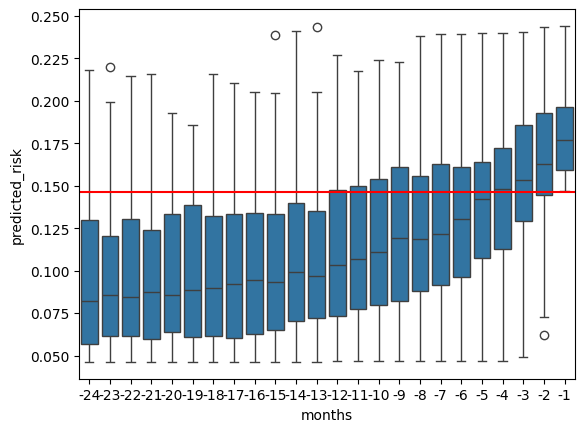

In [2]:
import pandas as pd
import seaborn as sns
import pylab as plt
df=pd.read_csv('./violin_plots_data.csv')
sns.boxplot(data=df,x='months',y='predicted_risk')
plt.axhline(0.14655972998295605,c='r')

In [3]:
import pandas as pd
import numpy as np

def make_screen_event_df_all(
    df,
    risk_threshold,
    patient_col="patient_id",
    month_col="months",
    risk_col="predicted_risk",
):
    df = df.copy()
    df = df.sort_values([patient_col, month_col])

    rows = []

    for pid, g in df.groupby(patient_col, sort=False):
        g = g.sort_values(month_col).reset_index(drop=True)

        crossed = g[g[risk_col] > risk_threshold]

        if crossed.empty:
            continue

        first_idx = crossed.index[0]

        screen_date = g.loc[first_idx, month_col]
        risk_crossing = g.loc[first_idx, risk_col]

        if first_idx > 0:
            risk_prev = g.loc[first_idx - 1, risk_col]
        else:
            risk_prev = np.nan

        delta_1 = risk_crossing - risk_prev if pd.notna(risk_prev) else np.nan

        rows.append({
            "patient_id": pid,
            "screen_date": screen_date,
            "event_date": -1,
            "risk_crossing": risk_crossing,
            "risk_prev": risk_prev,
            "delta_1": delta_1
        })

    return pd.DataFrame(rows)

def add_dynamic_risk_score(df):
    df = df.copy()

    rc = df["risk_crossing"]
    d1 = df["delta_1"]

    rc_z = (rc - rc.mean()) / rc.std()
    d1_z = (d1 - d1.mean()) / d1.std()

    df["risk_dynamic"] = rc_z + d1_z

    return df    




def redefine_risk_with_delta(
    df,
    level_col="risk_crossing",
    delta_col="delta_1",
    alpha=1.0,
):
    """
    Redefine risk_crossing to depend on both level and increase.

    new risk_crossing =
        z(level) + alpha * z(delta)

    alpha controls how strongly recent increase influences risk.
    alpha = 1.0 gives equal weight.
    """

    d = df.copy()

    d.risk_crossing = 0*(d.risk_prev) + 1*d.risk_crossing

    return d

In [6]:
df_=make_screen_event_df_all(df,risk_threshold=TH99)
df_

,patient_id,screen_date,event_date,risk_crossing,risk_prev,delta_1
0,1.018601e+06,-1,-1,0.149543,0.127247,0.022296
1,2.778300e+07,-5,-1,0.164255,0.103837,0.060418
2,1.396464e+08,-21,-1,0.160798,0.146397,0.014401
3,2.126150e+08,-1,-1,0.159715,0.117652,0.042063
4,5.350068e+08,-24,-1,0.177268,NaN,NaN
...,...,...,...,...,...,...
99,3.190233e+10,-6,-1,0.152709,0.084557,0.068152
100,3.190311e+10,-9,-1,0.157316,0.100319,0.056998
101,3.190329e+10,-1,-1,0.199062,0.104453,0.094609
102,3.194395e+10,-13,-1,0.150285,0.114721,0.035564


In [7]:
df_=make_screen_event_df_all(df,risk_threshold=TH99)
df_['event_date'] = df_.event_date-df_.screen_date
df_.screen_date = 0
#df_=df_.fillna(0)
#df_['newrisk'] = df_.risk_crossing/df_.delta_1
df_

,patient_id,screen_date,event_date,risk_crossing,risk_prev,delta_1
0,1.018601e+06,0,0,0.149543,0.127247,0.022296
1,2.778300e+07,0,4,0.164255,0.103837,0.060418
2,1.396464e+08,0,20,0.160798,0.146397,0.014401
3,2.126150e+08,0,0,0.159715,0.117652,0.042063
4,5.350068e+08,0,23,0.177268,NaN,NaN
...,...,...,...,...,...,...
99,3.190233e+10,0,5,0.152709,0.084557,0.068152
100,3.190311e+10,0,8,0.157316,0.100319,0.056998
101,3.190329e+10,0,0,0.199062,0.104453,0.094609
102,3.194395e+10,0,12,0.150285,0.114721,0.035564


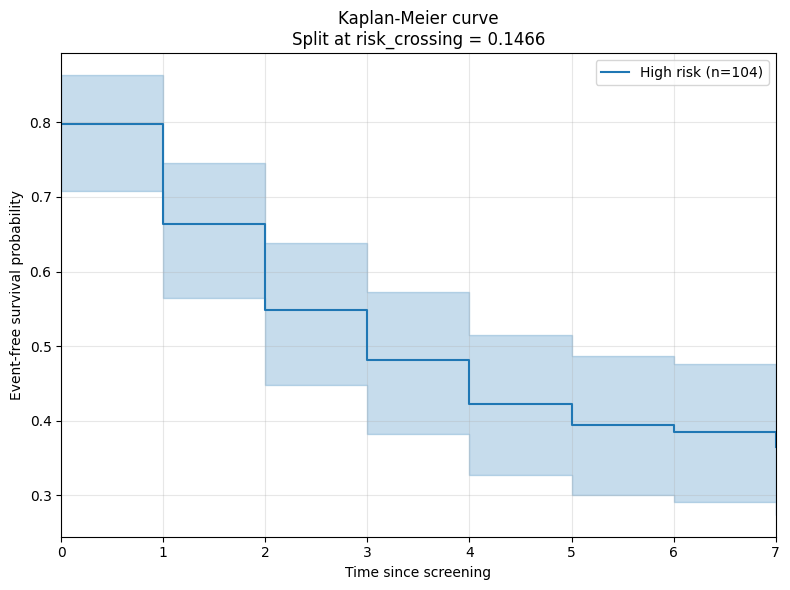

In [9]:
processed_df=make_km_plot(
    df_,
    screen_col="screen_date",
    event_col="event_date",
    risk_col="risk_crossing",
    max_followup=7,
    risk_split=TH99,#"median",   # "median", numeric threshold, or None
    title="Kaplan-Meier curve")